# 08. Nueva arquitectura 1D-CNN

**Objetivo:** desarrollar una arquitectura de red neuronal convolucional 1D modificada para la clasificación de enfermedad cardiovascular, utilizando una muestra estratificada de 15 000 registros y limitando el número de parámetros del modelo al intervalo de 30 000 a 50 000.


In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)


TensorFlow: 2.21.0
NumPy: 2.1.3


## 1. Configuración experimental

Se utiliza la muestra estratificada de 15 000 registros generada durante la auditoría del dataset. El identificador `id` no se utiliza como variable predictora y la variable `cardio` constituye la variable objetivo.


In [2]:
DATA_PATH = Path("../../resultados/nuevo_experimento/cardio_15000.csv")
OUT_DIR = Path("../../resultados/nuevo_experimento")
FIG_DIR = OUT_DIR / "figuras"
TAB_DIR = OUT_DIR / "tablas"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Dataset:", DATA_PATH)
print("Semilla:", RANDOM_STATE)


Dataset: ..\..\resultados\nuevo_experimento\cardio_15000.csv
Semilla: 42


In [3]:
df = pd.read_csv(DATA_PATH, sep=";")

print("Dimensiones:", df.shape)
print("Nulos:", int(df.isnull().sum().sum()))
print("Duplicados:", int(df.duplicated().sum()))
print("\nDistribución de cardio:")
print(df["cardio"].value_counts().sort_index())


Dimensiones: (15000, 13)
Nulos: 0
Duplicados: 0

Distribución de cardio:
cardio
0    7579
1    7421
Name: count, dtype: int64


## 2. Preparación de las variables

La columna `id` se excluye porque únicamente identifica el registro. La edad, almacenada originalmente en días, se transforma a años. La variable `cardio` se utiliza como objetivo binario.


In [4]:
df_model = df.copy()

df_model["age"] = df_model["age"] / 365.25

X = df_model.drop(columns=["id", "cardio"])
y = df_model["cardio"]

print("Dimensión de X:", X.shape)
print("Dimensión de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nNúmero de variables predictoras:", X.shape[1])


Dimensión de X: (15000, 11)
Dimensión de y: (15000,)

Variables predictoras:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Número de variables predictoras: 11


## 3. División entrenamiento, validación y prueba

Se utiliza una división 70/15/15 con estratificación respecto de `cardio`. La estratificación mantiene una distribución similar de las dos clases en los tres subconjuntos.


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Prueba:", X_test.shape, y_test.shape)

print("\nDistribución entrenamiento:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nDistribución validación:")
print(y_val.value_counts(normalize=True).sort_index())

print("\nDistribución prueba:")
print(y_test.value_counts(normalize=True).sort_index())


Entrenamiento: (10500, 11) (10500,)
Validación: (2250, 11) (2250,)
Prueba: (2250, 11) (2250,)

Distribución entrenamiento:
cardio
0    0.505238
1    0.494762
Name: proportion, dtype: float64

Distribución validación:
cardio
0    0.505333
1    0.494667
Name: proportion, dtype: float64

Distribución prueba:
cardio
0    0.505333
1    0.494667
Name: proportion, dtype: float64


## 4. Escalamiento

El escalador se ajusta exclusivamente con los datos de entrenamiento y posteriormente se aplica a validación y prueba. De esta manera se evita utilizar información de los subconjuntos de evaluación durante el ajuste del preprocesamiento.


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Train escalado:", X_train_scaled.shape)
print("Validation escalado:", X_val_scaled.shape)
print("Test escalado:", X_test_scaled.shape)


Train escalado: (10500, 11)
Validation escalado: (2250, 11)
Test escalado: (2250, 11)


## 5. Preparación de la entrada para 1D-CNN

La entrada se representa como:

`(número de registros, número de variables, canales)`

Por tanto, cada observación contiene 11 variables clínicas y un canal.


In [7]:
X_train_cnn = X_train_scaled[..., np.newaxis]
X_val_cnn = X_val_scaled[..., np.newaxis]
X_test_cnn = X_test_scaled[..., np.newaxis]

print("Entrada CNN:")
print("Train:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Test:", X_test_cnn.shape)

assert X_train_cnn.shape[1:] == (11, 1)
print("\nLa entrada cumple la forma esperada (11, 1).")


Entrada CNN:
Train: (10500, 11, 1)
Validation: (2250, 11, 1)
Test: (2250, 11, 1)

La entrada cumple la forma esperada (11, 1).


## 6. Diseño de la nueva arquitectura

La arquitectura se modifica respecto al modelo de referencia para reducir su complejidad y mantener el número de parámetros entre 30 000 y 50 000.

La estructura propuesta es:

**Entrada (11, 1) → Conv1D(32) → Conv1D(96) → GlobalAveragePooling1D → Dense(256) → Dropout(0.30) → salida sigmoid.**


In [8]:
model = Sequential([
    Input(shape=(11, 1)),

    Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),

    Conv1D(
        filters=96,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),

    GlobalAveragePooling1D(),

    Dense(
        256,
        activation="relu"
    ),

    Dropout(0.30),

    Dense(
        1,
        activation="sigmoid"
    )
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 11, 32)              │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 11, 96)              │           9,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 96)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │          24,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,529 (134.88 KB)

 Trainable params: 34,529 (134.88 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Verificación del número de parámetros

El modelo debe cumplir la restricción metodológica establecida para el experimento: entre 30 000 y 50 000 parámetros totales.


In [9]:
total_params = model.count_params()

print("========================================")
print("PARÁMETROS TOTALES:", total_params)
print("========================================")

assert 30000 <= total_params <= 50000, (
    f"La arquitectura tiene {total_params} parámetros y "
    "no cumple el rango 30 000–50 000."
)

print("✓ La arquitectura cumple el rango solicitado.")


PARÁMETROS TOTALES: 34529
✓ La arquitectura cumple el rango solicitado.


## 8. Compilación

Se utiliza Adam como optimizador y entropía cruzada binaria como función de pérdida, debido a que `cardio` representa una clasificación binaria.


In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Modelo compilado correctamente.")


Modelo compilado correctamente.


## 9. Entrenamiento

Se utiliza EarlyStopping para detener el entrenamiento cuando la pérdida de validación deje de mejorar y recuperar los mejores pesos encontrados.


In [11]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\nÉpocas ejecutadas:", len(history.history["loss"]))


Epoch 1/100


  1/329 ━━━━━━━━━━━━━━━━━━━━ 34:13 6s/step - accuracy: 0.5938 - loss: 0.6930 - precision: 0.3636 - recall: 0.4000

  5/329 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.6187 - loss: 0.6796 - precision: 0.6364 - recall: 0.2090 

  9/329 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5868 - loss: 0.6776 - precision: 0.6857 - recall: 0.1818

 16/329 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.5977 - loss: 0.6737 - precision: 0.7059 - recall: 0.2903

...

310/329 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7375 - loss: 0.5318 - precision: 0.7520 - recall: 0.6992

317/329 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7387 - loss: 0.5303 - precision: 0.7541 - recall: 0.6999

324/329 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7389 - loss: 0.5312 - precision: 0.7530 - recall: 0.7014

329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7388 - loss: 0.5313 - precision: 0.7533 - recall: 0.7018 - val_accuracy: 0.7169 - val_loss: 0.5665 - val_precision: 0.7220 - val_recall: 0.6954



Épocas ejecutadas: 44


## 10. Curvas de entrenamiento

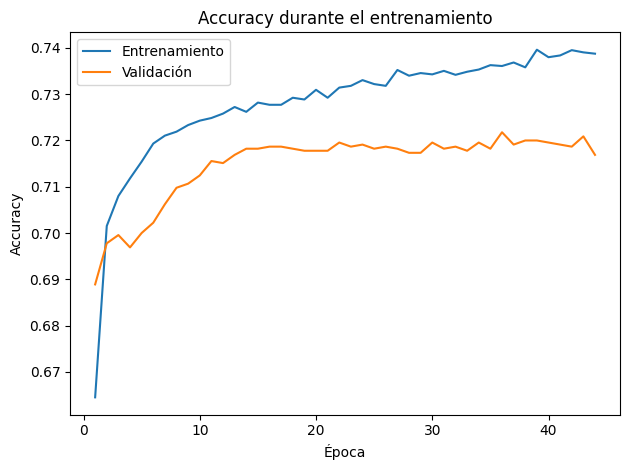

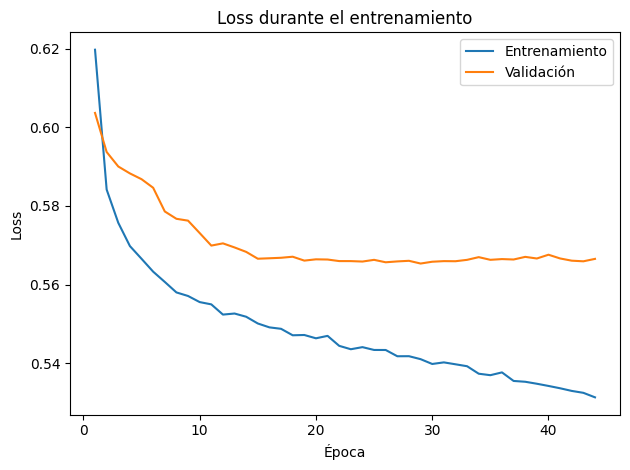

Historial guardado en: ..\..\resultados\nuevo_experimento\tablas\historial_nueva_cnn.csv


In [12]:
history_df = pd.DataFrame(history.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_path = TAB_DIR / "historial_nueva_cnn.csv"
history_df.to_csv(history_path)

fig, ax = plt.subplots()
ax.plot(history_df.index, history_df["accuracy"], label="Entrenamiento")
ax.plot(history_df.index, history_df["val_accuracy"], label="Validación")
ax.set_title("Accuracy durante el entrenamiento")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "curva_accuracy_nueva_cnn.png", dpi=300)
plt.show()

fig, ax = plt.subplots()
ax.plot(history_df.index, history_df["loss"], label="Entrenamiento")
ax.plot(history_df.index, history_df["val_loss"], label="Validación")
ax.set_title("Loss durante el entrenamiento")
ax.set_xlabel("Época")
ax.set_ylabel("Loss")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "curva_loss_nueva_cnn.png", dpi=300)
plt.show()

print("Historial guardado en:", history_path)


## 11. Evaluación sobre el conjunto de prueba

In [13]:
y_prob = model.predict(X_test_cnn, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

metrics_df = pd.DataFrame({
    "metrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "valor": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

metrics_path = TAB_DIR / "metricas_nueva_cnn.csv"
metrics_df.to_csv(metrics_path, index=False)

print(metrics_df.to_string(index=False))
print("\nMétricas guardadas en:", metrics_path)


  metrica    valor
 Accuracy 0.712444
Precision 0.716141
   Recall 0.693621
 F1-score 0.704701
  ROC-AUC 0.775738

Métricas guardadas en: ..\..\resultados\nuevo_experimento\tablas\metricas_nueva_cnn.csv


## 12. Reporte de clasificación

In [14]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Sin enfermedad", "Con enfermedad"],
        digits=4,
        zero_division=0
    )
)


                precision    recall  f1-score   support

Sin enfermedad     0.7090    0.7309    0.7198      1137
Con enfermedad     0.7161    0.6936    0.7047      1113

      accuracy                         0.7124      2250
     macro avg     0.7126    0.7122    0.7122      2250
  weighted avg     0.7126    0.7124    0.7123      2250



## 13. Matriz de confusión

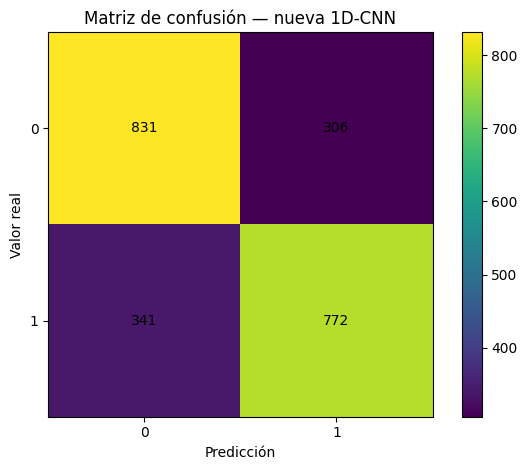

Matriz guardada en: ..\..\resultados\nuevo_experimento\figuras\matriz_confusion_nueva_cnn.png


In [15]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots()
im = ax.imshow(cm)
ax.set_title("Matriz de confusión — nueva 1D-CNN")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

fig.colorbar(im, ax=ax)
fig.tight_layout()

cm_path = FIG_DIR / "matriz_confusion_nueva_cnn.png"
fig.savefig(cm_path, dpi=300)
plt.show()

print("Matriz guardada en:", cm_path)


## 14. Curva ROC

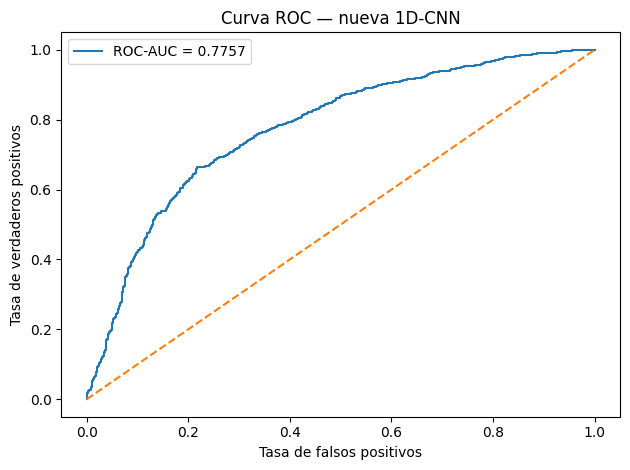

ROC guardada en: ..\..\resultados\nuevo_experimento\figuras\curva_roc_nueva_cnn.png


In [16]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_title("Curva ROC — nueva 1D-CNN")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.legend()
fig.tight_layout()

roc_path = FIG_DIR / "curva_roc_nueva_cnn.png"
fig.savefig(roc_path, dpi=300)
plt.show()

print("ROC guardada en:", roc_path)


## 15. Resumen experimental

In [17]:
summary = pd.DataFrame({
    "elemento": [
        "Registros utilizados",
        "Variables predictoras",
        "Entrenamiento",
        "Validación",
        "Prueba",
        "Parámetros del modelo",
        "Épocas máximas",
        "Épocas ejecutadas",
        "Batch size"
    ],
    "valor": [
        len(df),
        X.shape[1],
        len(X_train),
        len(X_val),
        len(X_test),
        total_params,
        100,
        len(history.history["loss"]),
        32
    ]
})

display(summary)

summary.to_csv(
    TAB_DIR / "resumen_nueva_cnn.csv",
    index=False
)


,elemento,valor
0,Registros utilizados,15000
1,Variables predictoras,11
2,Entrenamiento,10500
3,Validación,2250
4,Prueba,2250
5,Parámetros del modelo,34529
6,Épocas máximas,100
7,Épocas ejecutadas,44
8,Batch size,32


## 16. Conclusión

La nueva arquitectura 1D-CNN fue diseñada para reducir la cantidad de parámetros respecto del modelo de referencia y cumplir el intervalo de 30 000 a 50 000 parámetros establecido para el experimento. La evaluación sobre un conjunto de prueba independiente permitirá analizar su desempeño mediante Accuracy, Precision, Recall, F1-score y ROC-AUC.

Los resultados obtenidos se utilizarán posteriormente para comparar el comportamiento de la arquitectura modificada y discutir su relación con el objetivo de reducir la complejidad del modelo.
